# Python EDA
# Practice

In [3]:
# install modules
!pip install matplotlib seaborn numpy pandas

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached tzdata-2026.2-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -------- ------------------------------- 2.1/9.3 MB 11.8 MB/s eta 0:00:01
   ----------------- ---------------------- 4.2/9.3 MB 10.5 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.3 MB 10.6 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.3 MB 8.4 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 7.0 MB/s eta 0:00:01
   -------------------------------- ------- 7.6/9.3 MB 6.2 MB/s eta 0:00:01
   ------------------------------------- -- 8.7/9.3 MB 6.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 5.6 MB/s  0:00:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ---

In [25]:
# Import modules

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# read data
df_csv = pd.read_csv('data05.csv') # change path if you need
df_csv.head()
# Umut ILHAN
# Read the data from data05.csv
df = pd.read_csv('data05.csv')

# Display the first 10 elements
print("--- First 10 rows ---")
print(df.head(10))

# Check for missing data
print("\n--- Missing data count before cleaning ---")
print(df.isnull().sum())

# Resolve the problem by dropping rows with missing values (NaN)
df = df.dropna()

print("\n--- Missing data count after cleaning ---")
print(df.isnull().sum())

--- First 10 rows ---
   Country    Year        Attack Type     Target Industry  \
0    China  2019.0           Phishing           Education   
1    China  2019.0         Ransomware              Retail   
2    India  2017.0  Man-in-the-Middle                  IT   
3       UK  2024.0         Ransomware  Telecommunications   
4  Germany  2018.0  Man-in-the-Middle                  IT   
5  Germany  2017.0  Man-in-the-Middle              Retail   
6  Germany  2016.0               DDoS  Telecommunications   
7   France  2018.0      SQL Injection          Government   
8    India  2016.0  Man-in-the-Middle             Banking   
9       UK  2023.0               DDoS          Healthcare   

   Financial Loss (in Million $)  Number of Affected Users Attack Source  \
0                          80.53                  773169.0  Hacker Group   
1                          62.19                  295961.0  Hacker Group   
2                          38.65                  605895.0  Hacker Group   
3 

### Task 1
Perform an exploratory data analysis. Present your conclusions regarding the provided data and answer the questions below, supporting your responses with analytical evidence.

In [26]:
# TODO: EDA

Which sector is the most exposed to hacker attacks? How does the risk compare across other sectors?

### 1. Target Industry Analysis
This chart displays the frequency of cyberattacks across different industries. We can observe which sectors are most vulnerable by looking at the highest bars.

C:\Users\umuti\AppData\Local\Temp\ipykernel_14268\1043508116.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Target Industry', order=df['Target Industry'].value_counts().index, palette='viridis')


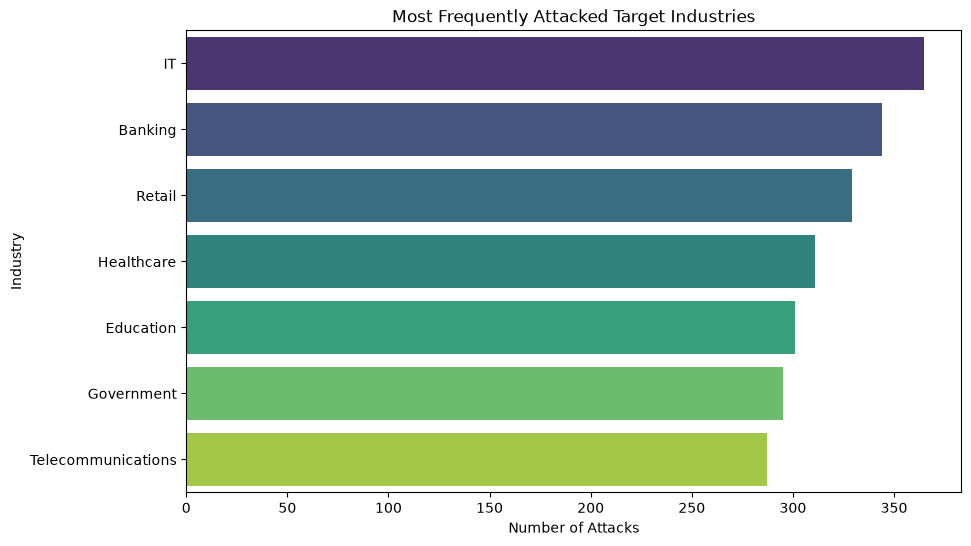

In [37]:
# Umut ILHAN
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='Target Industry', order=df['Target Industry'].value_counts().index, palette='viridis')
plt.title('Most Frequently Attacked Target Industries')
plt.xlabel('Number of Attacks')
plt.ylabel('Industry')
plt.show()

In which country were the greatest losses due to attacks recorded? What is the ratio of this value compared to losses in other countries?

### 2. Financial Loss by Country
The following pie chart visualizes the total financial loss recorded in each country. It highlights which country suffered the largest financial impact compared to the rest.

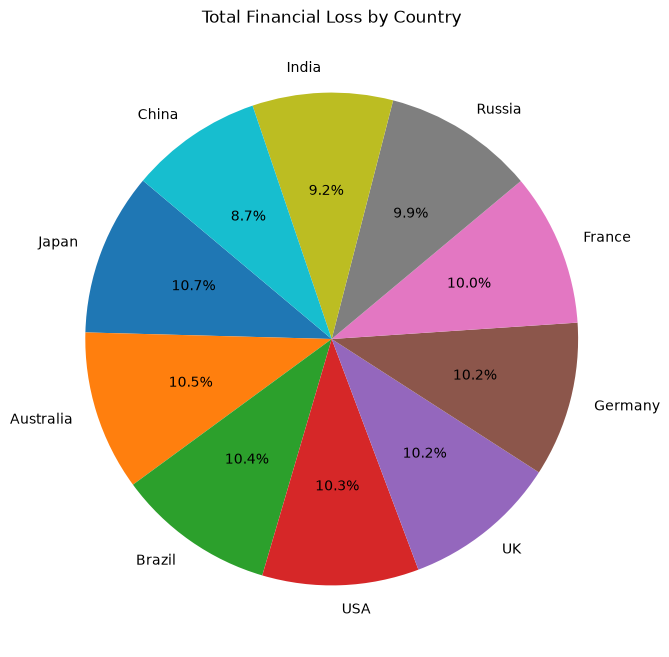

In [38]:
# Umut ILHAN
country_loss = df.groupby('Country')['Financial Loss (in Million $)'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 8))
plt.pie(country_loss, labels=country_loss.index, autopct='%1.1f%%', startangle=140)
plt.title('Total Financial Loss by Country')
plt.show()

Which types of attacks were the most frequent, and which were the least frequent over the years?

### 3. Attack Type Frequency
Here we analyze the most and least common types of cyberattacks. The bar plot sorts the attack methods by their occurrence, making it easy to identify the most frequent threats.

C:\Users\umuti\AppData\Local\Temp\ipykernel_14268\1204771774.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=attack_counts.values, y=attack_counts.index, palette='magma')


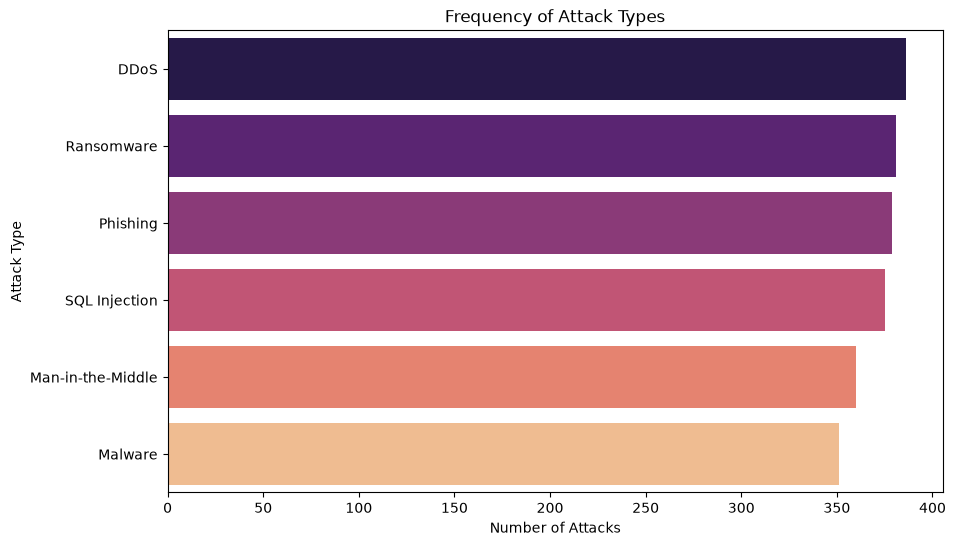

In [39]:
# Umut ILHAN
attack_counts = df['Attack Type'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=attack_counts.values, y=attack_counts.index, palette='magma')
plt.title('Frequency of Attack Types')
plt.xlabel('Number of Attacks')
plt.ylabel('Attack Type')
plt.show()

Are there relationships between the location of the attack, the attacking entity, the type of attack, and the target of the attack?

### 4. Relationships Between Variables
To explore the relationships between categorical variables like Attack Source and Target Industry, we use a heatmap based on cross-tabulation. This helps identify if specific attackers target certain industries more often.

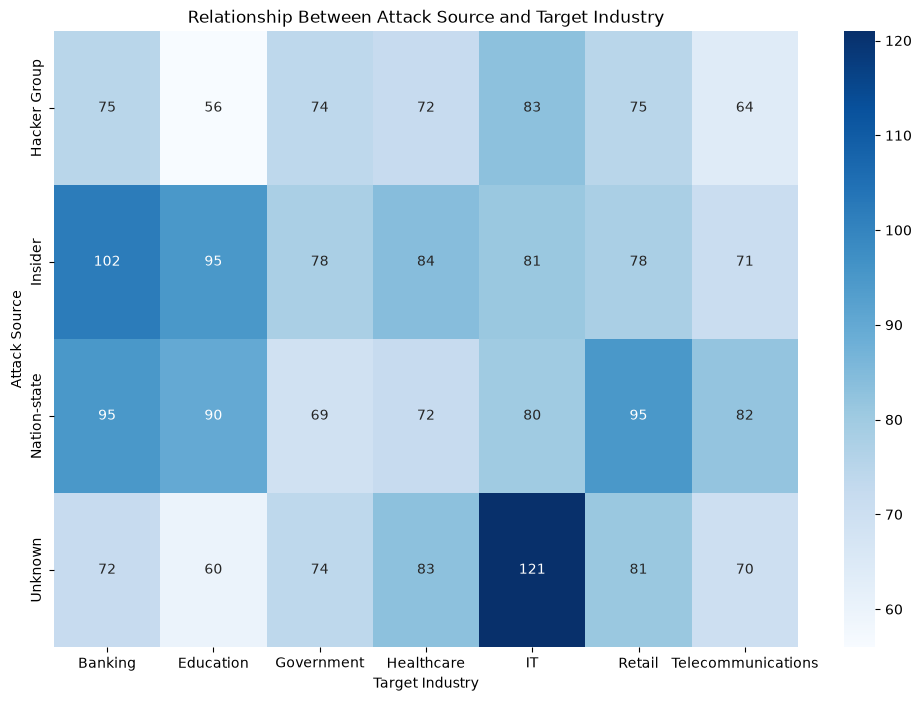

In [40]:
# Umut ILHAN
import pandas as pd

plt.figure(figsize=(12, 8))
crosstab_data = pd.crosstab(df['Attack Source'], df['Target Industry'])
sns.heatmap(crosstab_data, annot=True, fmt='d', cmap='Blues')
plt.title('Relationship Between Attack Source and Target Industry')
plt.xlabel('Target Industry')
plt.ylabel('Attack Source')
plt.show()

Do the data indicate whether it is more advantageous for an attacker for an attack to last as long as possible, or to affect as many users as possible?

### 5. Advantage of Attack Duration vs. Affected Users
By calculating the correlation matrix between Incident Resolution Time, Number of Affected Users, and Financial Loss, we can evaluate what brings more "advantage" (higher financial damage) to the attacker. The heatmap below shows these correlation coefficients.

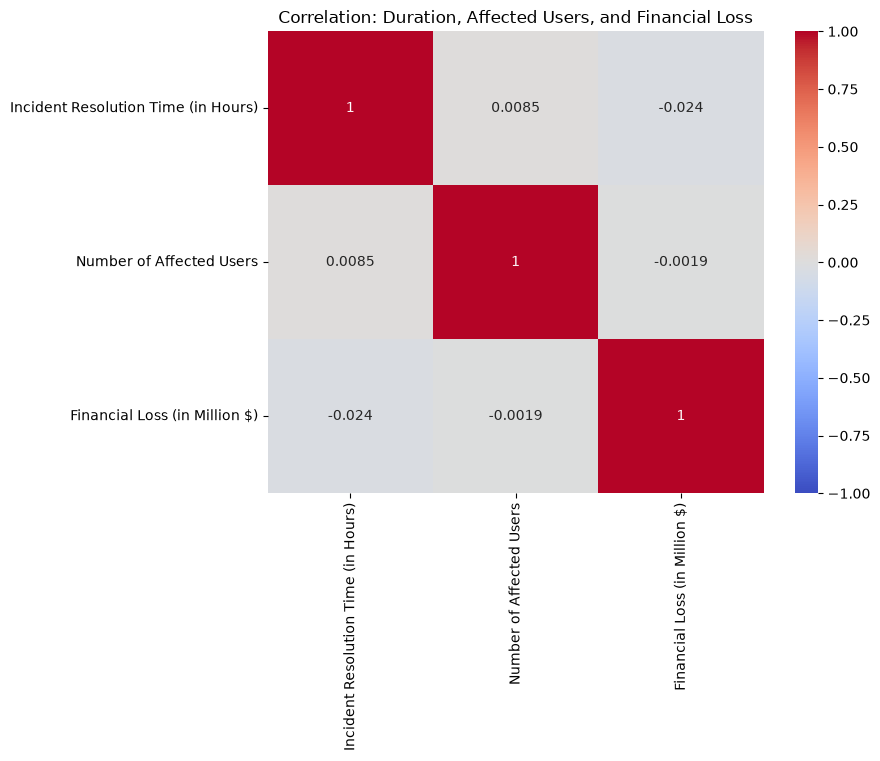

In [41]:
# Umut ILHAN
correlation_cols = ['Incident Resolution Time (in Hours)', 'Number of Affected Users', 'Financial Loss (in Million $)']
corr_matrix = df[correlation_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation: Duration, Affected Users, and Financial Loss')
plt.show()

How does the frequency of attacks change over the years? Is the trend decreasing, or on the contrary, increasing?

### 6. Attack Frequency Trend Over the Years
This line plot tracks the total number of cyberattacks year by year. It clearly illustrates whether the overall trend of attacks is increasing, decreasing, or remaining stable over time.

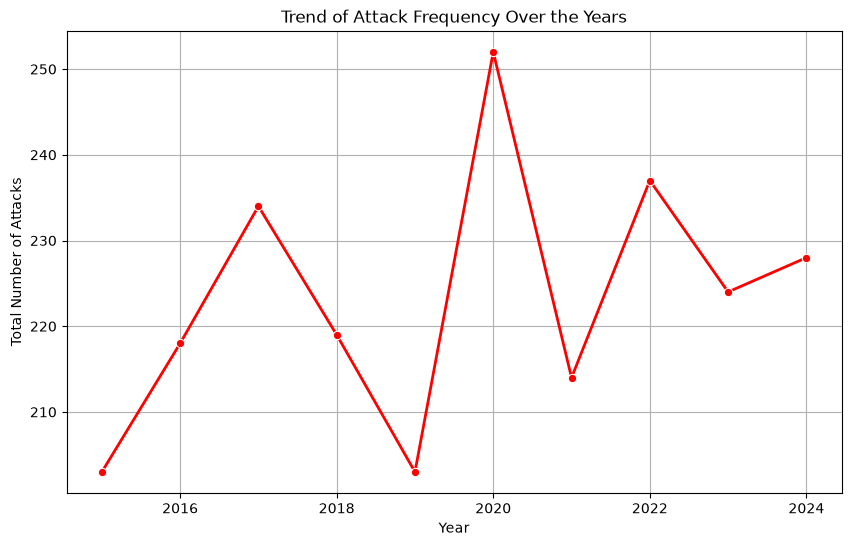

In [44]:
# Umut ILHAN
yearly_attacks = df.groupby('Year').size()

plt.figure(figsize=(10, 6))
sns.lineplot(x=yearly_attacks.index, y=yearly_attacks.values, marker='o', color='red', linewidth=2)
plt.title('Trend of Attack Frequency Over the Years')
plt.xlabel('Year')
plt.ylabel('Total Number of Attacks')
plt.grid(True)
plt.show()